In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from ou_hankel import (OUNetwork,
                       empirical_kalman_causality_probability)
from scipy.stats import rankdata
from mpl_toolkits.axes_grid1 import make_axes_locatable

n_nodes = 10      
n_reps  = 30     # independent graphs -- NOT a single network
h       = 0.5    # sampling period
seed0   = 0

plt.rcParams.update({
    # Font Family
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    
    # Consistent Font Sizes
    'font.size': 13,          # Base default text size
    'axes.labelsize': 13,     # X and Y axis labels
    'axes.titlesize': 13,     # Subplot titles
    'xtick.labelsize': 13,    # X-axis tick labels
    'ytick.labelsize': 13,    # Y-axis tick labels
    'legend.fontsize': 10,   # Legend text
    'figure.titlesize': 10,   # Overall figure title
})

N = 15
print(f"block depth N = {N}  (whitened Hankel is {2*N}x{2*N} for a pair)")

block depth N = 15  (whitened Hankel is 30x30 for a pair)


In [2]:
def roc_curve(labels, scores):
    thr = np.unique(scores)[::-1]
    P, Ng = labels.sum(), (~labels).sum()
    fpr, tpr = [0.0], [0.0]
    for t in thr:
        pred = scores >= t
        tpr.append((pred & labels).sum() / P)
        fpr.append((pred & ~labels).sum() / Ng)
    return np.asarray(fpr), np.asarray(tpr), thr

def auc_mw(labels, scores):
    r = rankdata(scores)                      # tie-corrected midranks
    P, Ng = labels.sum(), (~labels).sum()
    return (r[labels].sum() - P * (P + 1) / 2) / (P * Ng)


def roc_points(labels, scores):
    """ROC curve plus (fpr, tpr, thr) triples aligned across sklearn versions."""
    fpr, tpr, thr = roc_curve(labels, scores)
    thr = np.asarray(thr, dtype=float)
    k = len(thr)
    f, t = fpr[-k:], tpr[-k:]        # drop the prepended origin point
    m = np.isfinite(thr)             # drop thr[0] = inf on older sklearn
    return fpr, tpr, f[m], t[m], thr[m]


In [3]:
Ts = [5000, 10000]          
results = {}                     
for T in Ts:
    scores, labels = [], []
    for rep in range(n_reps):
        G = nx.barabasi_albert_graph(
            n_nodes,
            m=2,
            seed=seed0 + rep)
        # Randomly orient each edge
        rng = np.random.default_rng(seed0 + rep)
        G = nx.DiGraph(
            (u, v) if rng.random() < 0.5 else (v, u)
            for u, v in G.edges()
        )
        net = OUNetwork(G, seed=seed0 + rep)
        X = net.simulate(T, h, seed=10_000 + rep)
        for i in G.nodes:
            for j in G.nodes:
                if i == j:
                    continue
                ci, cj = [net.index[i]], [net.index[j]]
                res = empirical_kalman_causality_probability(X, ci, cj, N)
                scores.append(res["log_odds"])
                labels.append(nx.has_path(G, i, j))

    scores = np.asarray(scores)
    labels = np.asarray(labels, dtype=bool)
    results[T] = (scores, labels)

    print(f"T = {T}: {labels.sum()} causal / {labels.size} pairs "
          f"({n_reps} graphs x {n_nodes*(n_nodes-1)} ordered pairs); "
          f"log-odds range {scores.min():.0f} to {scores.max():.0f} nats")

T = 5000: 1581 causal / 2700 pairs (30 graphs x 90 ordered pairs); log-odds range -284 to 191 nats
T = 10000: 1581 causal / 2700 pairs (30 graphs x 90 ordered pairs); log-odds range -320 to 207 nats


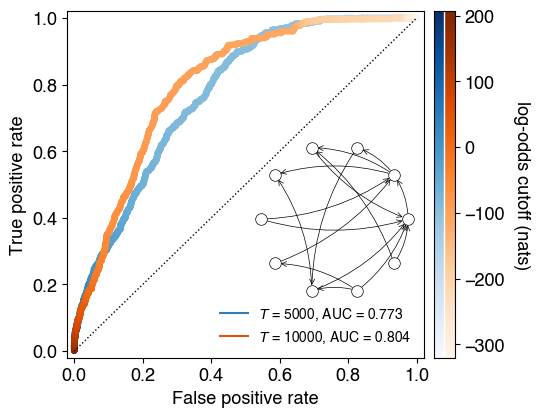

In [6]:
fig, ax = plt.subplots(figsize=(5, 4.5))

cmaps = ["Blues", "Oranges"]

# Common scale for both bars
all_thr = np.concatenate([
    roc_points(labels, scores)[4] for scores, labels in results.values()
])
norm = plt.Normalize(all_thr.min(), all_thr.max())

for (T, (scores, labels)), cmap_name in zip(results.items(), cmaps):
    fpr, tpr, f, t, th = roc_points(labels, scores)
    auc = auc_mw(labels, scores)

    ax.scatter(f, t, c=th, s=14, cmap=cmap_name, norm=norm, zorder=2)

    curve_color = plt.get_cmap(cmap_name)(0.7)
    ax.plot(fpr, tpr, "-", color=curve_color, lw=1.5, zorder=1,
            label=f"$T$ = {T}, AUC = {auc:.3f}")

ax.plot([0, 1], [0, 1], "k:", lw=1)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="lower right", frameon=False, ncol=1)

# ----------------------------------------------------------------------
# inset: representative graph from the ensemble (rep 0), plain vertices
# ----------------------------------------------------------------------
G_demo = nx.barabasi_albert_graph(
    n_nodes, m=2, seed=42)
_rng = np.random.default_rng(seed0)
G_demo = nx.DiGraph(
    (u, v) if _rng.random() < 0.5 else (v, u) for u, v in G_demo.edges()
)

pos = nx.circular_layout(G_demo)

ax_in = ax.inset_axes([0.5, 0.15, 0.5, 0.5])
ax_in.set_frame_on(False)

# nodes first
nx.draw_networkx_nodes(
    G_demo, pos, ax=ax_in, node_size=70,
    node_color="white", edgecolors="black", linewidths=0.5
)

# edges on top of nodes
nx.draw_networkx_edges(
    G_demo, pos, ax=ax_in, edge_color="k", width=0.5,
    arrows=True, arrowsize=9, arrowstyle="->",
    connectionstyle="arc3,rad=0.15",
    node_size=70, min_source_margin=2, min_target_margin=2
)

ax_in.set_axis_off()

# --- colorbar axis, locked to the height of ax ---
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="6%", pad=0.1)   # pad in inches

gradient = np.linspace(norm.vmin, norm.vmax, 256)[:, None]
for k, cmap_name in enumerate(cmaps):
    cax.imshow(gradient, aspect="auto", origin="lower",
               cmap=cmap_name, extent=(k, k + 1, norm.vmin, norm.vmax))

cax.axvline(1, color="white", lw=1)
cax.set_xlim(0, len(cmaps))
cax.set_ylim(norm.vmin, norm.vmax)
cax.set_xticks([])
cax.yaxis.tick_right()
cax.yaxis.set_label_position("right")
cax.set_ylabel("log-odds cutoff (nats)", rotation=270, labelpad=18)
cax.tick_params(axis="y", left=False, labelleft=False,
                right=True, labelright=True)

fig.savefig("plots/Figure4.pdf", bbox_inches="tight")
plt.show()